In [22]:
import numpy as np
import pandas as pd
from sklearn.decomposition import NMF
from sklearn.metrics import mean_squared_error
from math import sqrt

In [21]:
# Replace with your file path
df = pd.read_csv("movie_data.csv")


df = df.iloc[:, :3] # Select the first three columns.

# Expected columns: userId, movieId, rating
df.columns = ["userId", "movieId", "rating"]


In [5]:
user_item_matrix = df.pivot(index="userId", columns="movieId", values="rating")


In [6]:
user_item_filled = user_item_matrix.fillna(0)

In [10]:
#  Apply NMF Model
# -----------------------------
k = 10  # number of latent features

nmf_model = NMF(n_components=k, init='random', random_state=42, max_iter=200)

In [11]:
user_item_filled.columns = user_item_filled.columns.astype(str)
W = nmf_model.fit_transform(user_item_filled)   # User-feature matrix
H = nmf_model.components_                       # Item-feature matrix

In [12]:
reconstructed_matrix = np.dot(W, H)

# Convert back to DataFrame
reconstructed_df = pd.DataFrame(
    reconstructed_matrix,
    index=user_item_matrix.index,
    columns=user_item_matrix.columns
)

In [13]:
predictions = reconstructed_df


In [14]:
def recommend_movies(user_id, top_n=5):
    user_ratings = user_item_matrix.loc[user_id]
    predicted_ratings = predictions.loc[user_id]

    # Remove already rated movies
    unrated_movies = user_ratings[user_ratings.isna()].index

    # Sort predictions
    recommendations = predicted_ratings[unrated_movies].sort_values(ascending=False)

    return recommendations.head(top_n)

# Example
print("\nTop Recommendations for User 1:")
print(recommend_movies(user_id=1, top_n=5))


Top Recommendations for User 1:
movieId
David Fincher      2.370081e-02
Taylor Hackford    3.416623e-04
Michael Cimino     1.063669e-05
Rob Reiner         2.514124e-07
Danny Boyle        7.596947e-08
Name: 1, dtype: float64


In [17]:
mask = user_item_matrix.notna()
actual_ratings = user_item_matrix.values[mask.values]
predicted_ratings = reconstructed_df.values[mask.values]
rmse = sqrt(mean_squared_error(actual_ratings, predicted_ratings))
print("\nRMSE:", rmse)

# Precision@K and Recall@K
def precision_recall_at_k(k=5, threshold=3.5):
    precisions = []
    recalls = []

    for user in user_item_matrix.index:
        true_ratings = user_item_matrix.loc[user]
        pred_ratings = predictions.loc[user]

        relevant_items = true_ratings[true_ratings >= threshold].index
        recommended_items = pred_ratings.sort_values(ascending=False).head(k).index

        true_positive = len(set(recommended_items) & set(relevant_items))

        precision = true_positive / k if k else 0
        recall = true_positive / len(relevant_items) if len(relevant_items) else 0

        precisions.append(precision)
        recalls.append(recall)

    return np.mean(precisions), np.mean(recalls)

precision, recall = precision_recall_at_k(k=5)

print("\nPrecision@5:", precision)
print("Recall@5:", recall)


RMSE: 106.54519868036911

Precision@5: 0.016736069799722388
Recall@5: 0.08368034899861193


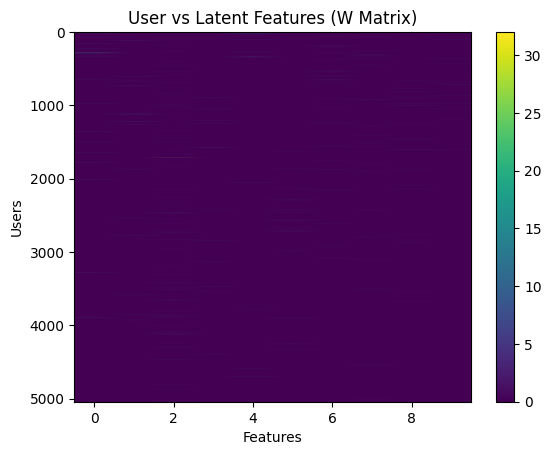

In [18]:
import matplotlib.pyplot as plt

plt.imshow(W, aspect='auto')
plt.colorbar()
plt.title("User vs Latent Features (W Matrix)")
plt.xlabel("Features")
plt.ylabel("Users")
plt.show()

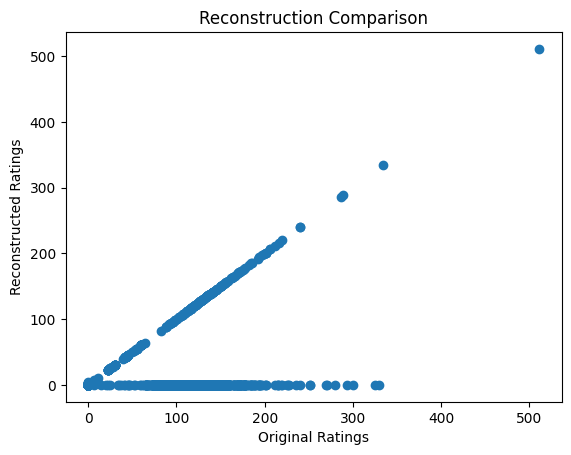

In [19]:
# Original vs Reconstructed values
original = user_item_filled.values.flatten()
reconstructed = reconstructed_df.values.flatten()

plt.scatter(original, reconstructed)
plt.xlabel("Original Ratings")
plt.ylabel("Reconstructed Ratings")
plt.title("Reconstruction Comparison")
plt.show()

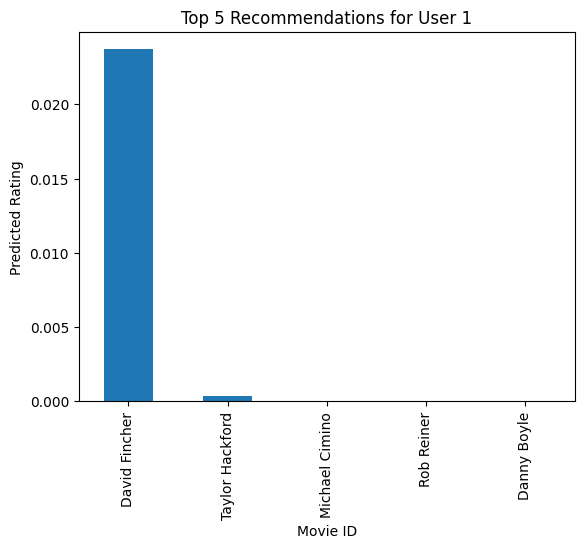

In [20]:
user_id = 1
top_n = 5

recommendations = recommend_movies(user_id, top_n)

recommendations.plot(kind='bar')
plt.title(f"Top {top_n} Recommendations for User {user_id}")
plt.xlabel("Movie ID")
plt.ylabel("Predicted Rating")
plt.show()